Chapter P1 asked the big question of this course: if nearly every cell has the same DNA, how do cells become different? The answer is **gene regulation**. A typical human cell uses perhaps 10,000–12,000 of its 20,000 protein-coding genes, and *which* ones, and how strongly, defines what the cell is. Cancer is, to a large extent, gene regulation gone wrong, and much of Part 2 (RNA-seq, single-cell analysis, deep learning on DNA) is about measuring or predicting it.

:::eli5
Think of the genome as a huge piano with 20,000 keys. Every cell has the same piano, but each cell type plays a different tune by pressing different keys. **Transcription factors** are the fingers that press keys: proteins that sit on DNA near a gene and turn it on or off. **Epigenetic marks** are like tape over some keys: in a skin cell, the keys for brain genes are taped down so they can't be played by accident, and the tape is copied when the cell divides.
:::

## Where regulation happens

The amount of protein made from a gene can be controlled at every step from chapter P4: transcription, splicing, mRNA lifetime, translation and protein lifetime. The biggest and best-studied control point is the first: **whether, and how often, the gene is transcribed**. The players:

| Element | What it is | Where |
|---|---|---|
| **Promoter** | DNA where RNA polymerase and its helpers assemble | just upstream of the transcription start site (TSS) |
| **Core promoter motifs** | short sequences such as the **TATA box** (TATAAA, about 30 bases upstream) | inside the promoter |
| **Transcription factors (TFs)** | proteins that recognise short DNA **motifs** (6–20 bases) and activate or repress | promoters and enhancers |
| **Enhancers** | clusters of TF binding sites that boost a gene, often from tens of thousands of bases away; the DNA loops to bring them to the promoter | anywhere, even inside other genes |
| **Silencers and insulators** | the opposite of enhancers, and boundaries that stop enhancers acting on the wrong gene | anywhere |

Humans have about 1,600 transcription factors, roughly 8% of all genes. Several famous cancer genes are TFs: **p53** (a tumour suppressor that switches on genes for DNA repair and cell death), **MYC** (an oncogene that boosts the growth programme), and the oestrogen receptor (the target of tamoxifen in breast cancer).

## A first circuit: the lac operon

The first regulatory circuit ever understood (by François Jacob and Jacques Monod, Nobel Prize 1965) is in *E. coli*. Bacteria prefer glucose, but can also eat the milk sugar lactose using three enzymes whose genes sit side by side (an **operon**). Making those enzymes costs energy, so the cell makes them only when they are useful: when lactose is present **and** glucose is absent. Two proteins implement that logic:

- The **lac repressor** sits on the operator and blocks transcription, unless lactose (as allolactose) pulls it off.
- The activator **CAP** binds next to the promoter and strongly recruits RNA polymerase, but only when glucose is low.

Try the four combinations in the playground's second tab.

::playground animations/regulation_lab.html 720

## Finding transcription-factor binding sites

A transcription factor recognises a short DNA pattern, but not one exact word: it tolerates variation at some positions and is strict at others. The standard way to describe that is a **position weight matrix** (PWM), built from many experimentally observed binding sites: for each position, how often each base appears.

The **JASPAR** database collects these matrices. We downloaded three: TBP (the protein that binds the TATA box), SP1 (a common activator that binds GC-rich "GC boxes") and p53. Let's load them and turn counts into scores.

:::math
For a matrix with counts $n_{b,j}$ (base $b$ at position $j$), first convert to probabilities with a small **pseudocount** so no base has probability zero:

$$p_{b,j} = \frac{n_{b,j} + 0.25}{\sum_{b'} n_{b',j} + 1}.$$

The score of a candidate site $x_1 x_2 \dots x_L$ is a sum of **log-odds**: how much more likely the base is under the motif than in background DNA (probability 0.25 each):

$$S(x) = \sum_{j=1}^{L} \log_2 \frac{p_{x_j, j}}{0.25}.$$

Each position contributes up to $\log_2(1/0.25) = 2$ bits. A position's **information content**, $2 + \sum_b p_{b,j}\log_2 p_{b,j}$, measures how picky the factor is there; it is the height of each stack in a **sequence logo**.
:::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import re

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
BASES = "ACGT"

def read_jaspar(path):
    lines = Path(path).read_text().splitlines()
    name = lines[0].split()[1]
    counts = np.array([[float(x) for x in re.findall(r"[\d.]+", l)] for l in lines[1:5]])
    return name, counts

def to_logodds(counts):
    p = (counts + 0.25) / (counts.sum(0) + 1)
    return p, np.log2(p / 0.25)

motifs = {}
for f in ["MA0108.2", "MA0079.5", "MA0106.3"]:
    name, counts = read_jaspar(f"datasets/{f}.jaspar")
    p, lo = to_logodds(counts)
    motifs[name] = (p, lo)
    consensus = "".join(BASES[i] for i in p.argmax(0))
    info = 2 + (p * np.log2(p)).sum(0)
    print(f"{name:5s} length {p.shape[1]:2d}  consensus {consensus:20s} total information {info.sum():5.1f} bits   best possible score {lo.max(0).sum():.1f}")

TBP   length 15  consensus GTATAAAAGGCGGGG      total information  10.0 bits   best possible score 16.2
SP1   length  9  consensus GGGGCGGGG            total information  14.3 bits   best possible score 16.5
TP53  length 18  consensus AACATGCCCGGGCATGTC   total information  20.7 bits   best possible score 28.4


Now a sequence logo for each, drawn with matplotlib: at each position, the letters are stacked with heights proportional to their probability times the information content.

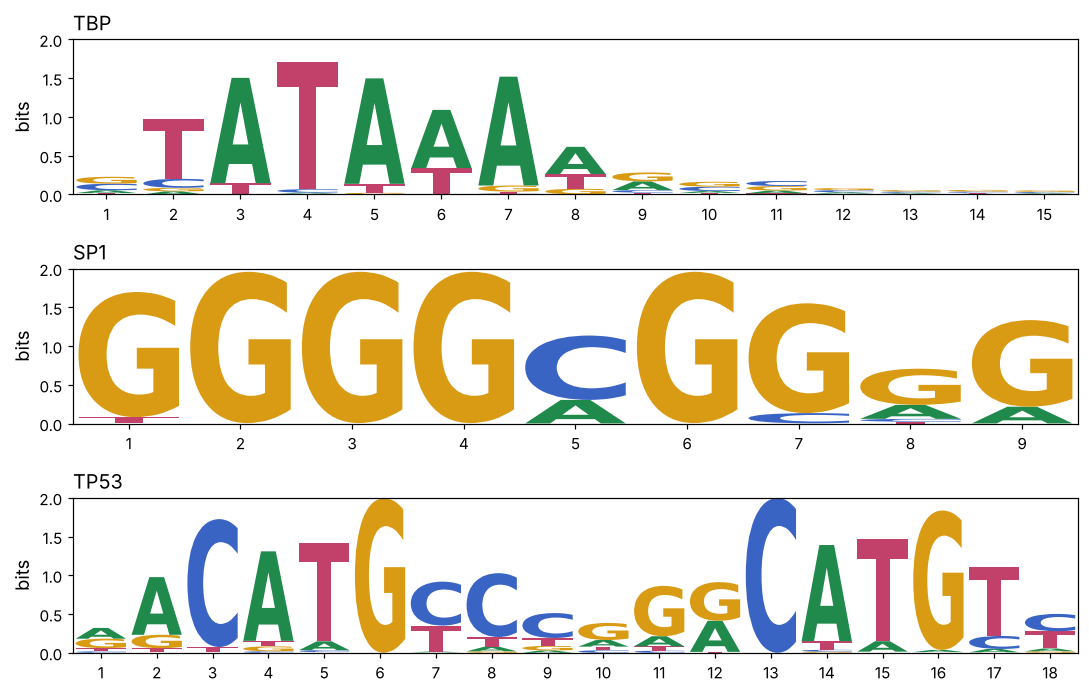

In [2]:
from matplotlib.textpath import TextPath
from matplotlib.patches import PathPatch
from matplotlib.transforms import Affine2D
COLS = {"A": "#1f8a4c", "C": "#3a64c4", "G": "#d99a14", "T": "#c2416b"}

def draw_letter(ax, letter, x, y, height):
    tp = TextPath((0, 0), letter, size=1, prop=mpl.font_manager.FontProperties(family="DejaVu Sans", weight="bold"))
    bb = tp.get_extents()
    tr = Affine2D().translate(-bb.x0, -bb.y0).scale(0.9 / bb.width, height / bb.height).translate(x + 0.05, y)
    ax.add_patch(PathPatch(tr.transform_path(tp), color=COLS[letter], lw=0))

fig, axs = plt.subplots(3, 1, figsize=(10, 6.4))
for ax, (name, (p, lo)) in zip(axs, motifs.items()):
    info = 2 + (p * np.log2(p)).sum(0)
    for j in range(p.shape[1]):
        y = 0
        for b in np.argsort(p[:, j]):
            hgt = p[b, j] * info[j]
            if hgt > 0.01:
                draw_letter(ax, BASES[b], j, y, hgt)
            y += hgt
    ax.set_xlim(0, p.shape[1]); ax.set_ylim(0, 2); ax.set_ylabel("bits"); ax.set_title(name, loc="left")
    ax.set_xticks(np.arange(p.shape[1]) + 0.5, range(1, p.shape[1] + 1))
save_fig("logos"); plt.show()

![Figure P6-1. Sequence logos for three transcription factors, from JASPAR. Tall letters are positions where the factor is strict. TBP recognises the AT-rich TATA box; SP1 recognises a GC-rich box; p53 binds two copies of a ten-base half-site, RRRCWWGYYY, back to back.](images/logos.png)

### Scanning a real promoter: p53 and the *CDKN1A* gene

When DNA is damaged, p53 switches on *CDKN1A*, whose protein p21 stops the cell cycle (chapter P7). That makes *CDKN1A* the textbook p53 target. We downloaded 20,000 bases of chromosome 6 around the gene. Let's slide the p53 matrix along both strands and score every position.

In [3]:
from Bio import SeqIO
region = str(SeqIO.read("datasets/CDKN1A_region.fasta", "fasta").seq).upper()
# the transcription start site: where the first 40 bases of the CDKN1A mRNA (NM_000389) sit in this region
mrna = str(SeqIO.read("datasets/NM_000389.fasta", "fasta").seq)
TSS = region.find(mrna[:40])
COMP = {"A": "T", "C": "G", "G": "C", "T": "A", "N": "N"}
IDX = {b: i for i, b in enumerate(BASES)}

def scan(seq, lo):
    """Best log-odds score on either strand for every window start."""
    L = lo.shape[1]
    onehot = np.zeros((4, len(seq)))
    for i, b in enumerate(seq):
        if b in IDX:
            onehot[IDX[b], i] = 1
    rc_lo = lo[::-1, ::-1]                                   # reverse complement of the matrix (A<->T, C<->G, reversed)
    fwd = np.array([(lo * onehot[:, i:i + L]).sum() for i in range(len(seq) - L + 1)])
    rev = np.array([(rc_lo * onehot[:, i:i + L]).sum() for i in range(len(seq) - L + 1)])
    return np.maximum(fwd, rev)

p53_p, p53_lo = motifs["TP53"]
scores = scan(region, p53_lo)
best = int(scores.argmax())
print(f"TSS found at index {TSS}")
print(f"best p53 site: {best - TSS:+d} bases from the TSS, score {scores[best]:.1f} of a possible {p53_lo.max(0).sum():.1f}")
print("sequence:", region[best:best + p53_lo.shape[1]])

TSS found at index 12251
best p53 site: -2264 bases from the TSS, score 22.2 of a possible 28.4
sequence: AACATGTCCCAACATGTT


The scan needs a reference point, the **transcription start site** (TSS). We placed it by searching for the start of the *CDKN1A* mRNA (RefSeq NM_000389) in the region. Is a high score meaningful, though? A PWM gives *some* score to every position, so we need to know how high random DNA can score. Shuffling the region keeps its base composition but destroys any real sites:

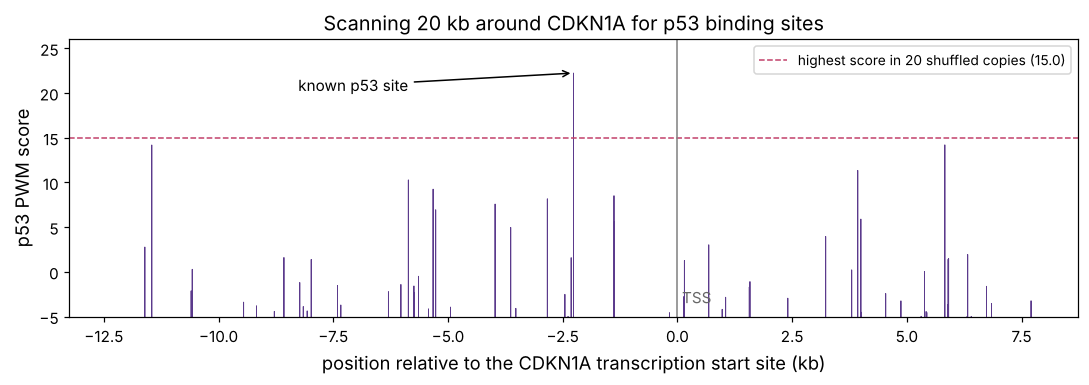

positions scoring above every shuffled copy: 1


In [4]:
rng = np.random.default_rng(0)
null_max = []
for _ in range(20):
    shuffled = "".join(rng.permutation(list(region)))
    null_max.append(scan(shuffled, p53_lo).max())

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(scores)) - TSS
ax.plot(x / 1000, scores, color="#5b3a8c", lw=0.6); ax.set_ylim(-5, 26)        # only the top of the score range matters
ax.axhline(max(null_max), color="#c2416b", ls="--", lw=1, label=f"highest score in 20 shuffled copies ({max(null_max):.1f})")
ax.axvline(0, color="0.5", lw=1); ax.text(0.1, -3.5, "TSS", color="0.4")
ax.annotate("known p53 site", (x[best] / 1000, scores[best]), xytext=(x[best] / 1000 - 6, scores[best] - 2), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("position relative to the CDKN1A transcription start site (kb)"); ax.set_ylabel("p53 PWM score"); ax.legend(loc="upper right", fontsize=9)
ax.set_title("Scanning 20 kb around CDKN1A for p53 binding sites")
save_fig("p53_scan"); plt.show()
n_hits = int((scores > max(null_max)).sum())
R["tss_dist"] = f"{best - TSS:+,}"; R["best_score"] = f"{scores[best]:.1f}"; R["null_max"] = f"{max(null_max):.1f}"
R["n_hits"] = n_hits; R["best_seq"] = region[best:best + p53_lo.shape[1]]
print(f"positions scoring above every shuffled copy: {n_hits}")

![Figure P6-2. p53 matrix scores along 20 kb of chromosome 6 around CDKN1A. One site stands far above anything found in shuffled DNA: the well-known p53 response element about 2.3 kb upstream of the gene.](images/p53_scan.png)

The best site, `AACATGTCCCAACATGTT`, sits -2,264 bases from the TSS with a score of 22.2. The best score in 20 shuffled copies of the region was only 15.0, so this is not luck. It is the p53 binding site that biologists mapped by experiment in the 1990s, about 2.3 kb upstream of the *CDKN1A* start: we rediscovered it from sequence alone. The smaller peak near −1.4 kb is the second p53 site reported in this promoter. It scores below the best shuffled position, a reminder that real, working sites are not always the top-scoring ones.

:::idea
Motif scanning has a big false-positive problem. Short motifs occur by chance everywhere: in 3 billion bases, even a site expected once per million bases appears thousands of times. Most predicted sites are never bound, because the DNA is wrapped in closed chromatin or the right partner proteins are missing. Real binding is measured with **ChIP-seq** (chapter P11), and deep-learning models (chapter 9) learn to predict binding from much wider sequence context.
:::

## CpG islands: a fingerprint of promoters

In the human genome, the two-letter word **CG** (written **CpG**, "C, phosphate, G") is strangely rare. The reason: the C in CpG is usually **methylated** (a methyl group added to it), and methylated C tends to mutate to T over evolutionary time, so CpGs slowly disappear. But around many promoters, CpGs are protected from methylation and survive in clusters called **CpG islands**. About 60–70% of human genes have one at their promoter.

The **observed/expected CpG ratio** measures this: the number of CG pairs, divided by the number expected from the counts of C and G.

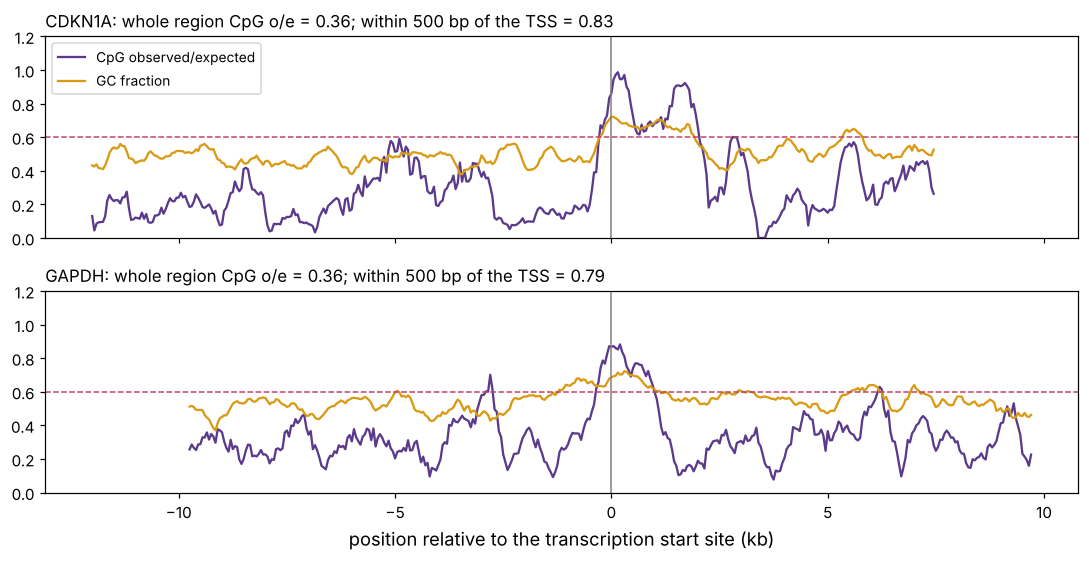

In [5]:
def cpg_oe(s):
    c, g = s.count("C"), s.count("G")
    return s.count("CG") * len(s) / (c * g) if c * g else 0

gapdh = str(SeqIO.read("datasets/GAPDH_region.fasta", "fasta").seq).upper()
regions = {"CDKN1A": (region, TSS), "GAPDH": (gapdh, 10000)}    # the GAPDH file is centred on its TSS
fig, axs = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
win, step = 500, 50
for ax, (gene, (seq, tss)) in zip(axs, regions.items()):
    starts = np.arange(0, len(seq) - win, step)
    oe = [cpg_oe(seq[s:s + win]) for s in starts]
    gc = [(seq[s:s + win].count("G") + seq[s:s + win].count("C")) / win for s in starts]
    xs = (starts + win / 2 - tss) / 1000
    ax.plot(xs, oe, color="#5b3a8c", label="CpG observed/expected"); ax.plot(xs, gc, color="#d99a14", label="GC fraction")
    ax.axhline(0.6, color="#c2416b", ls="--", lw=1); ax.axvline(0, color="0.5", lw=1)
    ax.set_title(f"{gene}: whole region CpG o/e = {cpg_oe(seq):.2f}; within 500 bp of the TSS = {cpg_oe(seq[tss - 500:tss + 500]):.2f}", fontsize=11, loc="left")
    ax.set_ylim(0, 1.2)
axs[0].legend(loc="upper left", fontsize=9); axs[1].set_xlabel("position relative to the transcription start site (kb)")
save_fig("cpg_islands"); plt.show()
R["oe_region"] = f"{cpg_oe(region):.2f}"; R["oe_tss"] = f"{cpg_oe(region[TSS - 500:TSS + 500]):.2f}"
R["oe_gapdh"] = f"{cpg_oe(gapdh[9500:10500]):.2f}"

![Figure P6-3. CpG observed/expected ratio (purple) and GC content (orange) in 500-base windows around two human genes. Away from genes, CpG is depleted (ratio about 0.2–0.4). At each transcription start site there is a CpG island, with the ratio rising above 0.6 (dashed line, a standard threshold).](images/cpg_islands.png)

Across the *CDKN1A* region the ratio is 0.36, but within 500 bases of its TSS it is 0.83; at the *GAPDH* promoter it is 0.79. CpG-island finders use exactly this calculation (with thresholds on length, GC content and o/e ratio) to locate promoters in newly sequenced genomes.

## Epigenetics: memory without changing the sequence

How does a liver cell stay a liver cell through many divisions? Its pattern of active and silent genes is written in chemical marks on the chromatin, and those marks are copied along with the DNA. This is **epigenetics** ("on top of genetics"): heritable changes in gene activity that do not change the DNA sequence.

| Mark | Effect | Example |
|---|---|---|
| **DNA methylation** at CpG islands | silences the promoter | silenced tumour suppressors in cancer (*MLH1*, *CDKN2A*) |
| **Histone acetylation** (e.g. H3K27ac) | opens chromatin; active promoters and enhancers | removed by HDACs; HDAC inhibitors treat some lymphomas |
| **H3K4me3** | marks active promoters | |
| **H3K27me3** | represses developmental genes (Polycomb) | EZH2 inhibitor tazemetostat |
| **H3K9me3** | tightly packed heterochromatin | repeats, centromeres |

"H3K27ac" is a code: **H**istone **3**, lysine (**K**) number **27**, **ac**etylated. The proteins that add marks are called **writers**, those that remove them **erasers**, and those that recognise them and act **readers**. All three are drug targets, and mutations in them are common in cancer.

The third tab of the playground lets you add and remove marks around a promoter.

:::bio
Two striking examples of epigenetic memory. **X inactivation**: females have two X chromosomes, and early in development each cell silences one at random, coating it with a non-coding RNA called *XIST*. The choice is inherited by all descendant cells, which is why tortoiseshell cats have patches of different colours. **Epigenetic clocks**: methylation at a few hundred CpG sites changes so steadily with age that a regression model on them (Horvath's clock, 2013) predicts a person's age within a few years. You will build models like this in Part 2.
:::

## Turning genes on and off: the dynamics

When a transcription factor switches a gene on, how quickly does the protein appear? A simple model has mRNA made at rate $k_m$ and destroyed at rate $\gamma_m$, and protein made from mRNA at rate $k_p$ and destroyed at rate $\gamma_p$:

:::math
$$\frac{dm}{dt} = k_m\,f(\text{TF}) - \gamma_m m, \qquad \frac{dp}{dt} = k_p\, m - \gamma_p p, \qquad f(x) = \frac{x^n}{K^n + x^n}.$$

$f$ is the **Hill function**: activity rises from 0 to 1 as the TF level $x$ passes $K$, more steeply when $n$ is large (several TF molecules binding cooperatively). After a sudden switch-on, $m(t) = m_\infty(1 - e^{-\gamma_m t})$: the mRNA approaches its steady state with a time scale of $1/\gamma_m$. Half-life $= \ln 2 / \gamma$.
:::

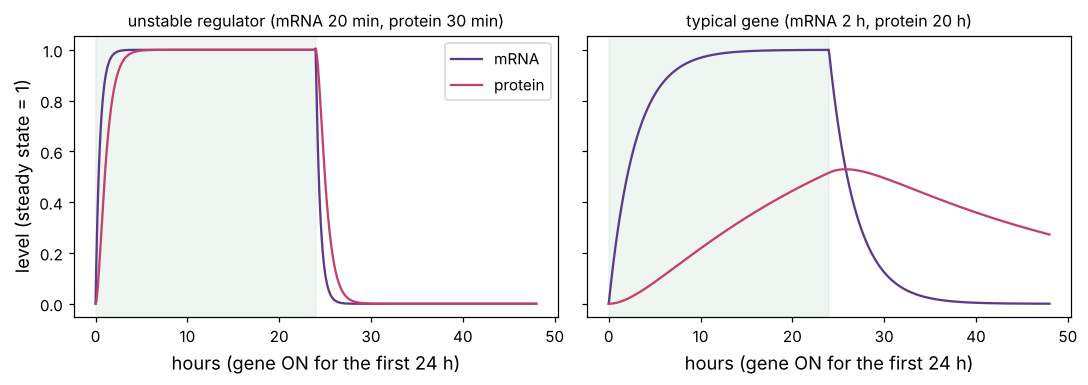

time to reach 90% of steady-state protein: 1.7 h (unstable) vs 66 h (stable)


In [6]:
from scipy.integrate import solve_ivp
def model(t, y, km, gm, kp, gp, on_until):
    m, p = y
    on = 1.0 if t < on_until else 0.0
    return [km * on - gm * m, kp * m - gp * p]

hl = {"unstable regulator (mRNA 20 min, protein 30 min)": (20, 30), "typical gene (mRNA 2 h, protein 20 h)": (120, 1200)}
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
t_eval = np.linspace(0, 48 * 60, 600)
for ax, (label, (hm, hp)) in zip(axs, hl.items()):
    gm, gp = np.log(2) / hm, np.log(2) / hp
    sol = solve_ivp(model, (0, t_eval[-1]), [0, 0], t_eval=t_eval, args=(gm, gm, gp, gp, 24 * 60), max_step=5)
    ax.plot(sol.t / 60, sol.y[0], color="#5b3a8c", label="mRNA"); ax.plot(sol.t / 60, sol.y[1], color="#c2416b", label="protein")
    ax.axvspan(0, 24, color="#1f8a4c", alpha=0.07); ax.set_title(label, fontsize=10.5); ax.set_xlabel("hours (gene ON for the first 24 h)")
axs[0].set_ylabel("level (steady state = 1)"); axs[0].legend()
save_fig("switch_dynamics"); plt.show()
t90 = lambda h: np.log(10) / (np.log(2) / h) / 60
R["t90_fast"] = f"{t90(30):.1f}"; R["t90_slow"] = f"{t90(1200):.0f}"
print(f"time to reach 90% of steady-state protein: {t90(30):.1f} h (unstable) vs {t90(1200):.0f} h (stable)")

![Figure P6-4. A gene switched on for 24 hours, then off. A regulator with short-lived mRNA and protein (left) responds within an hour or two in both directions. A typical stable protein (right) has not even reached its steady level after 24 hours and lingers for days after the gene is switched off.](images/switch_dynamics.png)

A protein with a 30-minute half-life reaches 90% of its final level in about 1.7 hours; one with a 20-hour half-life needs about 66 hours. **The speed of a response is set by how fast molecules are destroyed.** That is why the regulators that must react quickly (p53, MYC, cyclins) are among the most short-lived proteins in the cell, and why the first tab of the playground lets you play with half-lives. Chapter 17 builds full gene circuits (switches, oscillators) from equations like these.

## Cell identity and reprogramming

A cell's type is defined by a handful of **master transcription factors** that switch on each other and their target genes, in self-reinforcing loops, plus epigenetic marks that lock the pattern in. Shinya Yamanaka showed in 2006 that forcing just four TFs (OCT4, SOX2, KLF4 and MYC) into skin cells turns them back into stem cells (**induced pluripotent stem cells**, Nobel Prize 2012). Cell identity is therefore a stable, but changeable, state of the regulatory network.

Single-cell RNA-seq (chapter 7) reads out this state cell by cell: clusters of cells sharing an expression pattern are cell types, and the master TFs are among the genes that distinguish them.

:::lab
How regulation is measured: **RNA-seq** (which genes are on), **ChIP-seq** (where a given TF or histone mark sits on the genome), **ATAC-seq** (which regions are open chromatin), **bisulfite sequencing** (which Cs are methylated) and **Hi-C** (which distant regions touch in 3D). Chapter P11 explains how each works.
:::

## Summary

| Idea | One line |
|---|---|
| Promoter | where transcription starts; often a CpG island in humans |
| Transcription factor | protein that binds a short motif and activates or represses |
| PWM | per-position base probabilities; log-odds scores rank candidate sites |
| Enhancer | distant cluster of TF sites that loops to the promoter |
| Epigenetics | heritable marks on DNA and histones that lock genes on or off |
| Dynamics | response time is set by degradation rate (half-life) |

:::check
1. Why do CpG dinucleotides become rarer over evolution? *(Methylated C tends to mutate to T.)*
2. A PWM scan of 20 kb finds 40 sites above some threshold. Why might most of them be meaningless? *(Short motifs occur by chance; real binding also needs open chromatin and partner proteins.)*
3. In the lac operon, what happens with both lactose and glucose present? *(The repressor leaves, but CAP is not bound, so expression is low.)*
4. Protein A has a half-life of 10 minutes, protein B 10 hours. After their genes switch on, which reaches its steady level first? *(A.)*
5. What does H3K27me3 stand for? *(Histone 3, lysine 27, three methyl groups: a repressive mark.)*
:::

:::exercise
(a) Scan the same *CDKN1A* region with the TBP (TATA box) matrix. Is the best hit near the TSS? (b) Count how many positions in the region score above 80% of TBP's maximum possible score, and compare with the count in a shuffled copy. What does that tell you about the TATA box as a predictor of promoters?
:::

<details><summary>Solution</summary>

In [7]:
tbp_p, tbp_lo = motifs["TBP"]
tbp = scan(region, tbp_lo)
cut = 0.8 * tbp_lo.max(0).sum()
shuf = scan("".join(rng.permutation(list(region))), tbp_lo)
print(f"best TBP hit at {int(tbp.argmax()) - TSS:+d} from the TSS, score {tbp.max():.1f}")
print(f"positions above 80% of the maximum: real {int((tbp > cut).sum())}, shuffled {int((shuf > cut).sum())}")
near = tbp[TSS - 40:TSS - 20]
print(f"best score in the classic TATA window (-40 to -20): {near.max():.1f}")

best TBP hit at -6305 from the TSS, score 11.9
positions above 80% of the maximum: real 0, shuffled 1
best score in the classic TATA window (-40 to -20): 7.5


The best TATA-like hit is more than 6 kb from the promoter, and strong hits are as rare in the real region as in shuffled DNA: whatever AT-rich stretches exist score about as well anywhere. *CDKN1A*, like most human genes with CpG-island promoters, has no strong TATA box at −30. Only a minority of human promoters (roughly 10–20%) contain one. A single motif is a weak predictor; real promoter prediction combines many signals, which is exactly the job deep-learning models take on in chapter 9.

</details>